# نظام التشخيص المتكامل للجذام (End-to-End Diagnostic Pipeline)
### Stage 1 (جذام/لا) → Stage 2 (النوع) → خريطة الشدة السريرية → Explainable AI

## ⚠️ تنويه طبي مهم (لازم يُقرأ قبل الاستخدام)
هذا النظام هو **نموذج بحثي أكاديمي (Research Prototype)** وليس أداة تشخيص طبي
معتمدة، ولا بديلاً عن الفحص السريري بواسطة طبيب مختص. أي نتيجة يعرضها هذا
النظام يجب أن تُراجع وتُؤكد بواسطة طبيب جلدية أو أخصائي أمراض معدية قبل اتخاذ
أي قرار علاجي. النظام مبني على بيانات محدودة الحجم وقد يخطئ.

## مما يتكون النظام؟
1. **Stage 1 Ensemble** (EfficientNet-B3 + ConvNeXt-Tiny + ResNet50): هل الصورة جذام أم لا؟
2. **Stage 2 Model** (EfficientNet-B3 مُهيأ من Stage-1): لو جذام، أنهي نوع؟
3. **خريطة الشدة السريرية**: قاعدة طبية موثقة (WHO/Ridley-Jopling)، **ليست تعلم آلي**
4. **Explainable AI (Grad-CAM)**: خريطة حرارية توضح أنهي جزء من الصورة اعتمد
   عليه الموديل في قراره - مهمة جدًا للمصداقية العلمية في بحث طبي

## هذه النوتبوك مستقلة تمامًا
لا تحتاج تشغيل أي نوتبوك تدريب سابقة في نفس الجلسة - فقط تحتاج ملفات الـ
checkpoints المحفوظة على Google Drive من قبل.


## 1) تركيب المكتبات

In [ ]:
!pip install -q torch torchvision pillow matplotlib

## 2) ربط Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3) الإعدادات: مسارات كل الـ checkpoints المطلوبة

In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/skin_disease_project"

STAGE1_CHECKPOINTS = {
    "efficientnet_b3": os.path.join(PROJECT_DIR, "outputs/checkpoints/efficientnet_b3_best.pt"),
    "convnext_tiny":   os.path.join(PROJECT_DIR, "outputs/checkpoints/convnext_tiny_best.pt"),
    "resnet50":        os.path.join(PROJECT_DIR, "outputs/checkpoints/resnet50_best.pt"),
}
STAGE1_CLASSES = ["leprosy", "non_leprosy"]

STAGE2_CHECKPOINT = os.path.join(PROJECT_DIR, "stage2_leprosy_subtype/checkpoints/stage1_finetuned_foldFINAL_best.pt")
STAGE2_SUBTYPES = ["Leprosy Tuberculoid", "Leprosy Lepromatous", "Leprosy Borderline"]

IMAGE_SIZE = 300
DROPOUT_RATE = 0.4

BUNDLE_DIR = os.path.join(PROJECT_DIR, "model_bundle_final")
os.makedirs(BUNDLE_DIR, exist_ok=True)

print("الإعدادات جاهزة ✅")


الإعدادات جاهزة ✅


## 4) التحقق من وجود كل الملفات + تجميعها في حزمة واحدة (Model Bundle)

In [ ]:
import shutil, json, datetime

print("=" * 70)
print("فحص ملفات Stage 1:")
print("=" * 70)
all_ok = True
for name, path in STAGE1_CHECKPOINTS.items():
    exists = os.path.exists(path)
    size_mb = os.path.getsize(path) / (1024 ** 2) if exists else 0
    print(f"{'✅' if exists else '❌'} {name}: {path} ({size_mb:.1f} MB)")
    all_ok = all_ok and exists

print("\n" + "=" * 70)
print("فحص ملف Stage 2:")
print("=" * 70)
exists2 = os.path.exists(STAGE2_CHECKPOINT)
size2 = os.path.getsize(STAGE2_CHECKPOINT) / (1024 ** 2) if exists2 else 0
print(f"{'✅' if exists2 else '❌'} Stage2 model: {STAGE2_CHECKPOINT} ({size2:.1f} MB)")
all_ok = all_ok and exists2

if not all_ok:
    print("\n⚠️  فيه ملفات ناقصة! راجعي المسارات في خلية الإعدادات قبل ما تكملي.")
else:
    print("\n✅ كل الملفات موجودة وسليمة.")
    for name, path in STAGE1_CHECKPOINTS.items():
        shutil.copy2(path, os.path.join(BUNDLE_DIR, f"stage1_{name}.pt"))
    shutil.copy2(STAGE2_CHECKPOINT, os.path.join(BUNDLE_DIR, "stage2_final_model.pt"))

    manifest = {
        "created_at": str(datetime.datetime.now()),
        "stage1_classes": STAGE1_CLASSES,
        "stage2_subtypes": STAGE2_SUBTYPES,
        "image_size": IMAGE_SIZE,
        "dropout_rate": DROPOUT_RATE,
        "stage2_init_strategy_used": "stage1_finetuned",
        "note": "حزمة كاملة self-contained - لا حاجة لإعادة أي تدريب لاستخدامها.",
    }
    with open(os.path.join(BUNDLE_DIR, "manifest.json"), "w", encoding="utf-8") as f:
        json.dump(manifest, f, ensure_ascii=False, indent=2)
    print(f"\n✅ تم تجميع كل الملفات في: {BUNDLE_DIR}")


فحص ملفات Stage 1:
✅ efficientnet_b3: /content/drive/MyDrive/skin_disease_project/outputs/checkpoints/efficientnet_b3_best.pt (41.4 MB)
✅ convnext_tiny: /content/drive/MyDrive/skin_disease_project/outputs/checkpoints/convnext_tiny_best.pt (106.2 MB)
✅ resnet50: /content/drive/MyDrive/skin_disease_project/outputs/checkpoints/resnet50_best.pt (90.0 MB)

فحص ملف Stage 2:
✅ Stage2 model: /content/drive/MyDrive/skin_disease_project/stage2_leprosy_subtype/checkpoints/stage1_finetuned_foldFINAL_best.pt (41.4 MB)

✅ كل الملفات موجودة وسليمة.

✅ تم تجميع كل الملفات في: /content/drive/MyDrive/skin_disease_project/model_bundle_final


## 5) بناء معماريات الموديلات (Stage 1 ثنائي + Stage 2 ثلاثي)

In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image

def get_device():
    return torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

DEVICE = get_device()
print(f"الجهاز: {DEVICE}")


def build_stage1_model(arch_name):
    if arch_name == "efficientnet_b3":
        model = models.efficientnet_b3(weights=None)
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(p=DROPOUT_RATE), nn.Linear(in_features, 2))
    elif arch_name == "convnext_tiny":
        model = models.convnext_tiny(weights=None)
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(nn.Dropout(p=DROPOUT_RATE), nn.Linear(in_features, 2))
    elif arch_name == "resnet50":
        model = models.resnet50(weights=None)
        in_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(p=DROPOUT_RATE), nn.Linear(in_features, 2))
    else:
        raise ValueError(arch_name)
    return model


def build_stage2_model():
    model = models.efficientnet_b3(weights=None)
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(nn.Dropout(p=DROPOUT_RATE), nn.Linear(in_features, 3))
    return model

print("دوال بناء الموديلات جاهزة ✅")


الجهاز: cuda
دوال بناء الموديلات جاهزة ✅


## 6) تحميل كل الموديلات المدربة

In [ ]:
stage1_models = {}
for name, path in STAGE1_CHECKPOINTS.items():
    model = build_stage1_model(name)
    model.load_state_dict(torch.load(path, map_location=DEVICE))
    model.to(DEVICE)
    model.eval()
    stage1_models[name] = model
    print(f"✅ تم تحميل Stage 1 - {name}")

stage2_model = build_stage2_model()
stage2_model.load_state_dict(torch.load(STAGE2_CHECKPOINT, map_location=DEVICE))
stage2_model.to(DEVICE)
stage2_model.eval()
print("✅ تم تحميل Stage 2 - EfficientNet-B3 (stage1_finetuned)")

print("\n🎉 كل الموديلات جاهزة للاستخدام - مفيش أي تدريب لازم يحصل تاني.")


✅ تم تحميل Stage 1 - efficientnet_b3
✅ تم تحميل Stage 1 - convnext_tiny
✅ تم تحميل Stage 1 - resnet50
✅ تم تحميل Stage 2 - EfficientNet-B3 (stage1_finetuned)

🎉 كل الموديلات جاهزة للاستخدام - مفيش أي تدريب لازم يحصل تاني.


## 7) خريطة الشدة السريرية (Clinical Severity Mapping)
⚠️ **هذه ليست نموذج تعلم آلي** - قاعدة سريرية مبنية على التصنيف الطبي المعتمد
عالميًا (WHO / Ridley-Jopling)، لعدم توفر بيانات شدة موسومة في الداتاست.

In [ ]:
SEVERITY_MAP = {
    "Leprosy Tuberculoid": {
        "severity": "خفيفة (Mild / Paucibacillary)",
        "rationale": "استجابة مناعية خلوية قوية تحصر المرض في عدد قليل من الآفات، عدوى أقل، ضرر عصبي محدود غالبًا.",
    },
    "Leprosy Borderline": {
        "severity": "متوسطة (Moderate / حالة انتقالية غير مستقرة)",
        "rationale": "خصائص مشتركة بين النوعين، وممكن تتحول بمرور الوقت لأخف أو لأشد بدون علاج.",
    },
    "Leprosy Lepromatous": {
        "severity": "شديدة (Severe / Multibacillary)",
        "rationale": "استجابة مناعية خلوية ضعيفة، انتشار بكتيري واسع، عدوى جهازية أشد، خطر أعلى لضرر عصبي دائم.",
    },
}

print("خريطة الشدة السريرية جاهزة ✅ (قاعدة طبية موثقة - ليست موديل متعلم)")
for subtype, info in SEVERITY_MAP.items():
    print(f"\n{subtype} → {info['severity']}")


خريطة الشدة السريرية جاهزة ✅ (قاعدة طبية موثقة - ليست موديل متعلم)

Leprosy Tuberculoid → خفيفة (Mild / Paucibacillary)

Leprosy Borderline → متوسطة (Moderate / حالة انتقالية غير مستقرة)

Leprosy Lepromatous → شديدة (Severe / Multibacillary)


## 8) دالة التشخيص الكاملة (Stage 1 → Stage 2 → الشدة)

In [ ]:
import torch.nn.functional as F
import numpy as np

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

inference_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def preprocess_image(image_path):
    img = Image.open(image_path).convert("RGB")
    tensor = inference_transform(img).unsqueeze(0).to(DEVICE)
    return img, tensor


def diagnose(image_path, leprosy_threshold=0.5):
    img, tensor = preprocess_image(image_path)

    stage1_probs = []
    with torch.no_grad():
        for name, model in stage1_models.items():
            output = model(tensor)
            probs = F.softmax(output, dim=1).cpu().numpy()[0]
            stage1_probs.append(probs)

    avg_stage1_probs = np.mean(stage1_probs, axis=0)
    leprosy_idx = STAGE1_CLASSES.index("leprosy")
    leprosy_confidence = avg_stage1_probs[leprosy_idx]
    is_leprosy = leprosy_confidence >= leprosy_threshold

    report = {
        "image_path": image_path,
        "stage1_prediction": "Leprosy" if is_leprosy else "Non-Leprosy",
        "stage1_confidence": float(leprosy_confidence if is_leprosy else 1 - leprosy_confidence),
        "leprosy_idx": leprosy_idx,
    }

    if not is_leprosy:
        report["subtype"] = None
        report["subtype_confidence"] = None
        report["subtype_idx"] = None
        report["severity"] = None
        return report, img, tensor

    with torch.no_grad():
        output2 = stage2_model(tensor)
        probs2 = F.softmax(output2, dim=1).cpu().numpy()[0]

    subtype_idx = int(np.argmax(probs2))
    subtype_name = STAGE2_SUBTYPES[subtype_idx]
    subtype_confidence = float(probs2[subtype_idx])
    severity_info = SEVERITY_MAP[subtype_name]

    report["subtype"] = subtype_name
    report["subtype_confidence"] = subtype_confidence
    report["subtype_idx"] = subtype_idx
    report["severity"] = severity_info["severity"]
    report["severity_rationale"] = severity_info["rationale"]
    report["all_subtype_probs"] = {STAGE2_SUBTYPES[i]: float(probs2[i]) for i in range(len(STAGE2_SUBTYPES))}

    return report, img, tensor


def print_diagnostic_report(report):
    print("=" * 70)
    print("🏥 تقرير التشخيص (نظام بحثي - يحتاج تأكيد من طبيب مختص)")
    print("=" * 70)
    print(f"Stage 1 - هل جذام؟  →  {report['stage1_prediction']}  (ثقة: {report['stage1_confidence']*100:.1f}%)")

    if report["stage1_prediction"] == "Non-Leprosy":
        print("\n✅ لا يوجد مؤشر على الجذام حسب النموذج.")
    else:
        print(f"Stage 2 - النوع  →  {report['subtype']}  (ثقة: {report['subtype_confidence']*100:.1f}%)")
        print(f"الشدة السريرية (قاعدة طبية)  →  {report['severity']}")
        print(f"  السبب: {report['severity_rationale']}")
        print("\nاحتمالات كل الأنواع:")
        for subtype, prob in report["all_subtype_probs"].items():
            print(f"  {subtype}: {prob*100:.1f}%")
        if report["subtype_confidence"] < 0.6:
            print("\n⚠️  ثقة النموذج منخفضة نسبيًا - يُنصح بمراجعة طبية دقيقة.")

    print("\n" + "=" * 70)
    print("⚠️ هذا النظام بحثي وليس بديلاً عن تشخيص طبيب مختص.")
    print("=" * 70)

print("دالة التشخيص جاهزة ✅")


دالة التشخيص جاهزة ✅


## 9) Explainable AI: Grad-CAM
### ليه Grad-CAM بالتحديد؟
Grad-CAM بيوضح **أنهي بكسلات في الصورة أثّرت أكتر على قرار الموديل**، عن طريق
حساب تدرجات (gradients) الفئة المتوقعة بالنسبة لآخر طبقة Convolution، وتحويلها
لخريطة حرارية (Heatmap) نقدر نظبطها فوق الصورة الأصلية. ده بيدّي دليل بصري
مهم جدًا لمصداقية البحث: **هل الموديل فعلاً بيبص على الآفة الجلدية، ولا على
تفاصيل عشوائية في الخلفية (زي لون الإضاءة أو حواف الصورة)؟**

### الطبقات المستهدفة لكل معمارية
- EfficientNet-B3 / ConvNeXt-Tiny: آخر طبقة في `model.features`
- ResNet50: آخر Block في `model.layer4`

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm


class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx):
        self.model.zero_grad()
        output = self.model(input_tensor)
        score = output[0, class_idx]
        score.backward()

        gradients = self.gradients[0]      # (C, H, W)
        activations = self.activations[0]  # (C, H, W)
        weights = gradients.mean(dim=(1, 2))  # (C,)

        cam = torch.zeros(activations.shape[1:], dtype=torch.float32, device=activations.device)
        for i, w in enumerate(weights):
            cam += w * activations[i]

        cam = torch.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam.cpu().numpy()


def get_target_layer(arch_name, model):
    if arch_name in ("efficientnet_b3", "convnext_tiny"):
        return model.features[-1]
    elif arch_name == "resnet50":
        return model.layer4[-1]
    else:
        raise ValueError(arch_name)

def overlay_heatmap(pil_image, cam, alpha=0.45):
    img_resized = pil_image.resize((IMAGE_SIZE, IMAGE_SIZE))
    img_arr = np.array(img_resized).astype(np.float32) / 255.0

    cam_img = Image.fromarray((cam * 255).astype(np.uint8)).resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)
    cam_resized = np.array(cam_img).astype(np.float32) / 255.0

    heatmap = cm.jet(cam_resized)[:, :, :3]
    overlay = (1 - alpha) * img_arr + alpha * heatmap
    return np.clip(overlay, 0, 1)


def generate_stage1_gradcam(tensor, pil_image, leprosy_idx):
    """متوسط خرائط Grad-CAM من الموديلات الثلاثة (تفسير أقرب لقرار الـ Ensemble الفعلي)."""
    cams = []
    for name, model in stage1_models.items():
        target_layer = get_target_layer(name, model)
        gradcam = GradCAM(model, target_layer)
        with torch.enable_grad():
            cam = gradcam.generate(tensor.clone(), leprosy_idx)
        cam_resized = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize((IMAGE_SIZE, IMAGE_SIZE))) / 255.0
        cams.append(cam_resized)
    avg_cam = np.mean(cams, axis=0)
    return overlay_heatmap(pil_image, avg_cam)


def generate_stage2_gradcam(tensor, pil_image, subtype_idx):
    target_layer = get_target_layer("efficientnet_b3", stage2_model)
    gradcam = GradCAM(stage2_model, target_layer)
    with torch.enable_grad():
        cam = gradcam.generate(tensor.clone(), subtype_idx)
    return overlay_heatmap(pil_image, cam)


def show_explainability(report, img, tensor):
    """يعرض الصورة الأصلية + خريطة Grad-CAM لكل مرحلة حصلت فعليًا."""
    n_panels = 1 + (1 if report["stage1_prediction"] == "Leprosy" else 0) * 2
    fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 5))
    if n_panels == 1:
        axes = [axes]

    axes[0].imshow(img)
    axes[0].set_title("الصورة الأصلية")
    axes[0].axis("off")

    stage1_cam = generate_stage1_gradcam(tensor, img, report["leprosy_idx"])
    axes[1].imshow(stage1_cam)
    axes[1].set_title(f"Grad-CAM: قرار الجذام\n(Stage 1 Ensemble - متوسط 3 موديلات)")
    axes[1].axis("off")

    if report["stage1_prediction"] == "Leprosy":
        stage2_cam = generate_stage2_gradcam(tensor, img, report["subtype_idx"])
        axes[2].imshow(stage2_cam)
        axes[2].set_title(f"Grad-CAM: قرار النوع\n({report['subtype']})")
        axes[2].axis("off")

    plt.tight_layout()
    plt.show()
    print("🔍 الألوان الأدفأ (أحمر/أصفر) = المناطق اللي أثّرت أكتر على قرار الموديل.")

print("Grad-CAM جاهز ✅")


Grad-CAM جاهز ✅


## 10) الاستخدام التفاعلي: ارفعي صورة واحصلي على تشخيص كامل + تفسير بصري

ارفعي صورة الجلد المراد تشخيصها:


Saving 3319.jpg to 3319.jpg
🏥 تقرير التشخيص (نظام بحثي - يحتاج تأكيد من طبيب مختص)
Stage 1 - هل جذام؟  →  Leprosy  (ثقة: 97.0%)
Stage 2 - النوع  →  Leprosy Borderline  (ثقة: 96.8%)
الشدة السريرية (قاعدة طبية)  →  متوسطة (Moderate / حالة انتقالية غير مستقرة)
  السبب: خصائص مشتركة بين النوعين، وممكن تتحول بمرور الوقت لأخف أو لأشد بدون علاج.

احتمالات كل الأنواع:
  Leprosy Tuberculoid: 1.1%
  Leprosy Lepromatous: 2.1%
  Leprosy Borderline: 96.8%

⚠️ هذا النظام بحثي وليس بديلاً عن تشخيص طبيب مختص.

🔍 التفسير البصري (Explainable AI - Grad-CAM)


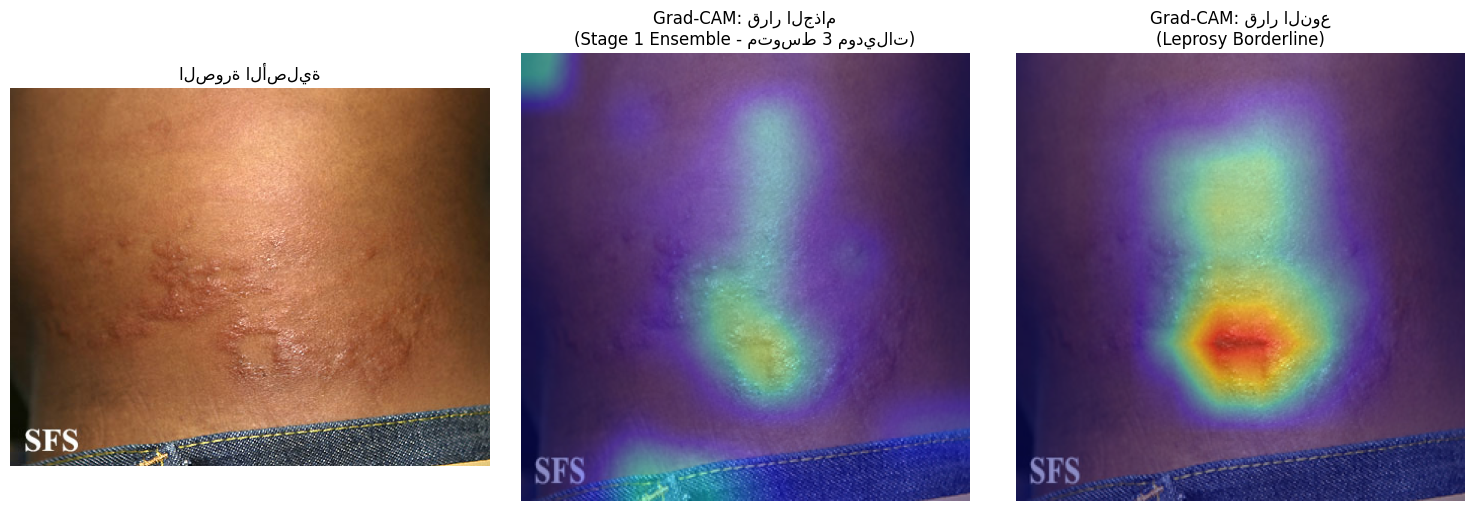

🔍 الألوان الأدفأ (أحمر/أصفر) = المناطق اللي أثّرت أكتر على قرار الموديل.


In [ ]:
from google.colab import files

print("ارفعي صورة الجلد المراد تشخيصها:")
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

report, img, tensor = diagnose(image_path)
print_diagnostic_report(report)

print("\n" + "=" * 70)
print("🔍 التفسير البصري (Explainable AI - Grad-CAM)")
print("=" * 70)
show_explainability(report, img, tensor)


1) الحل السريع: تنقية الخريطة الحرارية بصريًا (Thresholding)

المشكلة جزء منها إن Grad-CAM بيلوّن كل درجات التنشيط حتى الضعيفة جدًا (عشان كده بتظهر بقعة زرقاء/خضراء خفيفة حتى لو تأثيرها ضئيل جدًا على القرار الفعلي). الحل: نطبّق threshold يشيل أي تنشيط أضعف من نسبة معينة من أعلى قيمة، فالخريطة تركز بس على المنطقة الأهم فعليًا وتوضح الصورة أنضف بصريًا (من غير ما نغيّر قرار الموديل نفسه خالص — ده تحسين للعرض بس).

# New Section
sigma=5                    # تنعيم الخريطة
threshold_percentile=60    # نسبة القطع
keep_largest_only=True     # الاحتفاظ بأكبر منطقة متصلة بس

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.ndimage import gaussian_filter, label


class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx):
        self.model.zero_grad()
        output = self.model(input_tensor)
        score = output[0, class_idx]
        score.backward()

        gradients = self.gradients[0]      # (C, H, W)
        activations = self.activations[0]  # (C, H, W)
        weights = gradients.mean(dim=(1, 2))  # (C,)

        cam = torch.zeros(activations.shape[1:], dtype=torch.float32, device=activations.device)
        for i, w in enumerate(weights):
            cam += w * activations[i]

        cam = torch.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam.cpu().numpy()


def get_target_layer(arch_name, model):
    if arch_name in ("efficientnet_b3", "convnext_tiny"):
        return model.features[-1]
    elif arch_name == "resnet50":
        return model.layer4[-1]
    else:
        raise ValueError(arch_name)


def overlay_heatmap(pil_image, cam, alpha=0.45, threshold_percentile=60, keep_largest_only=True):
    """
    threshold_percentile: أي تنشيط أضعف من النسبة المئوية دي هيتشال تمامًا.
    sigma=5 (بدل 8): تنعيم أخف عشان منولدش جسور اصطناعية بين مناطق بعيدة
    (زي منطقة الآفة ومنطقة حزام الجينز في الصورة).
    keep_largest_only: يحتفظ بأكبر منطقة متصلة بس ويشيل أي جزر معزولة.
    """
    img_resized = pil_image.resize((IMAGE_SIZE, IMAGE_SIZE))
    img_arr = np.array(img_resized).astype(np.float32) / 255.0

    cam_img = Image.fromarray((cam * 255).astype(np.uint8)).resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)
    cam_resized = np.array(cam_img).astype(np.float32) / 255.0

    # ---- تنعيم أخف من قبل (5 بدل 8) ----
    cam_resized = gaussian_filter(cam_resized, sigma=5)

    # ---- رفع الـ threshold لـ60% عشان نقطع أي جسر ضعيف قبل حساب الاتصال ----
    threshold_value = np.percentile(cam_resized, threshold_percentile)
    binary_mask = cam_resized >= threshold_value

    # ---- الاحتفاظ بأكبر منطقة متصلة بس ----
    if keep_largest_only:
        labeled_mask, num_features = label(binary_mask)
        if num_features > 1:
            component_sizes = np.bincount(labeled_mask.ravel())
            component_sizes[0] = 0
            largest_component_id = component_sizes.argmax()
            binary_mask = labeled_mask == largest_component_id

    cam_clean = np.where(binary_mask, cam_resized, 0)
    if cam_clean.max() > 0:
        cam_clean = cam_clean / cam_clean.max()

    heatmap = cm.jet(cam_clean)[:, :, :3]

    # ---- تنعيم حافة المنطقة (انتقال تدريجي) ----
    alpha_mask = gaussian_filter((cam_clean > 0).astype(np.float32), sigma=4) * alpha
    alpha_mask = alpha_mask[:, :, np.newaxis]

    overlay = (1 - alpha_mask) * img_arr + alpha_mask * heatmap
    return np.clip(overlay, 0, 1)


def generate_stage1_gradcam(tensor, pil_image, leprosy_idx):
    """متوسط خرائط Grad-CAM من الموديلات الثلاثة (تفسير أقرب لقرار الـ Ensemble الفعلي)."""
    cams = []
    for name, model in stage1_models.items():
        target_layer = get_target_layer(name, model)
        gradcam = GradCAM(model, target_layer)
        with torch.enable_grad():
            cam = gradcam.generate(tensor.clone(), leprosy_idx)
        cam_resized = np.array(Image.fromarray((cam * 255).astype(np.uint8)).resize((IMAGE_SIZE, IMAGE_SIZE))) / 255.0
        cams.append(cam_resized)
    avg_cam = np.mean(cams, axis=0)
    return overlay_heatmap(pil_image, avg_cam)


def generate_stage2_gradcam(tensor, pil_image, subtype_idx):
    target_layer = get_target_layer("efficientnet_b3", stage2_model)
    gradcam = GradCAM(stage2_model, target_layer)
    with torch.enable_grad():
        cam = gradcam.generate(tensor.clone(), subtype_idx)
    return overlay_heatmap(pil_image, cam)


def show_explainability(report, img, tensor):
    """يعرض الصورة الأصلية + خريطة Grad-CAM لكل مرحلة حصلت فعليًا."""
    n_panels = 1 + (1 if report["stage1_prediction"] == "Leprosy" else 0) * 2
    fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 5))
    if n_panels == 1:
        axes = [axes]

    axes[0].imshow(img)
    axes[0].set_title("الصورة الأصلية")
    axes[0].axis("off")

    stage1_cam = generate_stage1_gradcam(tensor, img, report["leprosy_idx"])
    axes[1].imshow(stage1_cam)
    axes[1].set_title(f"Grad-CAM: قرار الجذام\n(Stage 1 Ensemble - متوسط 3 موديلات)")
    axes[1].axis("off")

    if report["stage1_prediction"] == "Leprosy":
        stage2_cam = generate_stage2_gradcam(tensor, img, report["subtype_idx"])
        axes[2].imshow(stage2_cam)
        axes[2].set_title(f"Grad-CAM: قرار النوع\n({report['subtype']})")
        axes[2].axis("off")

    plt.tight_layout()
    plt.show()
    print("🔍 الألوان الأدفأ (أحمر/أصفر) = المناطق اللي أثّرت أكتر على قرار الموديل.")

print("Grad-CAM جاهز ✅ (threshold=60%, sigma=5, أكبر منطقة متصلة بس)")

Grad-CAM جاهز ✅ (threshold=60%, sigma=5, أكبر منطقة متصلة بس)


ارفعي صورة الجلد المراد تشخيصها:


Saving 3295.jpg to 3295.jpg
🏥 تقرير التشخيص (نظام بحثي - يحتاج تأكيد من طبيب مختص)
Stage 1 - هل جذام؟  →  Leprosy  (ثقة: 93.9%)
Stage 2 - النوع  →  Leprosy Borderline  (ثقة: 89.9%)
الشدة السريرية (قاعدة طبية)  →  متوسطة (Moderate / حالة انتقالية غير مستقرة)
  السبب: خصائص مشتركة بين النوعين، وممكن تتحول بمرور الوقت لأخف أو لأشد بدون علاج.

احتمالات كل الأنواع:
  Leprosy Tuberculoid: 6.6%
  Leprosy Lepromatous: 3.4%
  Leprosy Borderline: 89.9%

⚠️ هذا النظام بحثي وليس بديلاً عن تشخيص طبيب مختص.

🔍 التفسير البصري (Explainable AI - Grad-CAM)


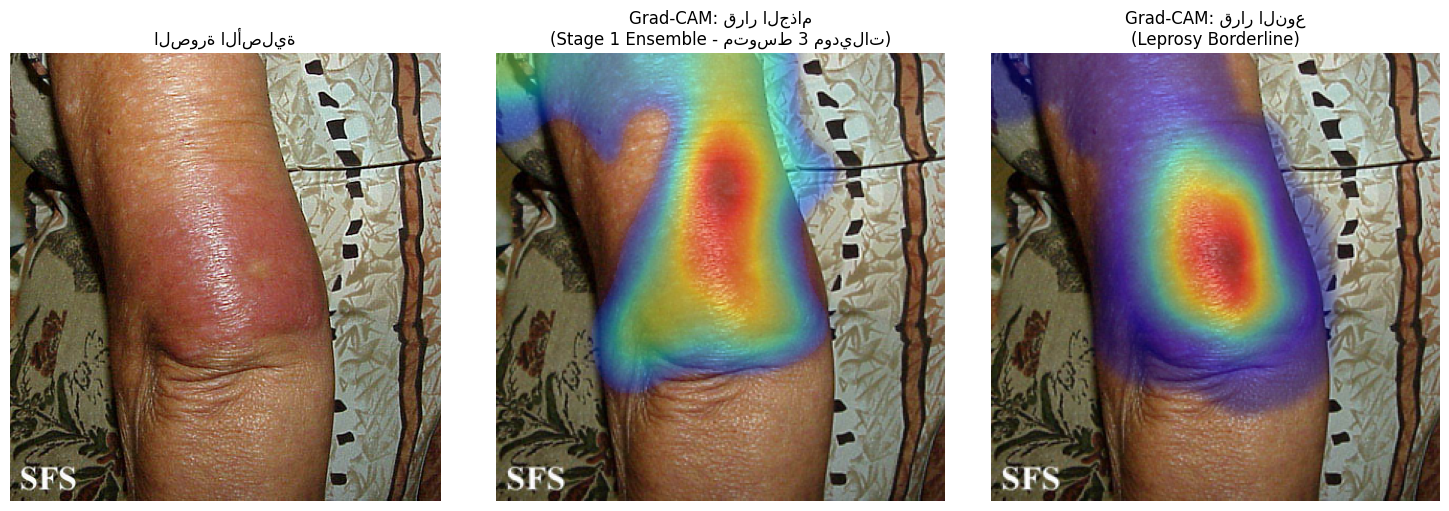

🔍 الألوان الأدفأ (أحمر/أصفر) = المناطق اللي أثّرت أكتر على قرار الموديل.


In [ ]:
from google.colab import files

print("ارفعي صورة الجلد المراد تشخيصها:")
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

report, img, tensor = diagnose(image_path)
print_diagnostic_report(report)

print("\n" + "=" * 70)
print("🔍 التفسير البصري (Explainable AI - Grad-CAM)")
print("=" * 70)
show_explainability(report, img, tensor)